lets generate a mesh from a set of points. note that we can rotate the pv.PolyData object using rotate_z

In [1]:
import tempfile
import pyvista as pv
import numpy as np
import os
from IPython.display import Image
import importlib

from ntrfc.gmsh.turbo_cascade import generate_turbocascade , MeshConfig
from ntrfc.cascade_case.utils.domain_utils import DomainParameters
from ntrfc.cascade_case.domain import CascadeDomain2D
from ntrfc.filehandling.mesh import load_mesh

# we need a display some situations like a cicd run
if os.getenv('DISPLAY') is None:
    pv.start_xvfb()  # Start X virtual framebuffer (Xvfb)


In [2]:
profilepoints_file = importlib.resources.files("ntrfc") / "data/turbine_cascade/profilepoints.txt"


points = np.loadtxt(profilepoints_file)
pts = pv.PolyData(points)

ratio of cleaned sites: 0.8073422026607983


/home/many/miniconda3/envs/NTRfC/lib/python3.10/site-packages/pyvista/core/filters/poly_data.py:2848: PyVistaFutureWarning: The default value of the ``capping`` keyword argument will change in a future version to ``True`` to match the behavior of VTK. We recommend passing the keyword explicitly to prevent future surprises.
  warnings.warn(


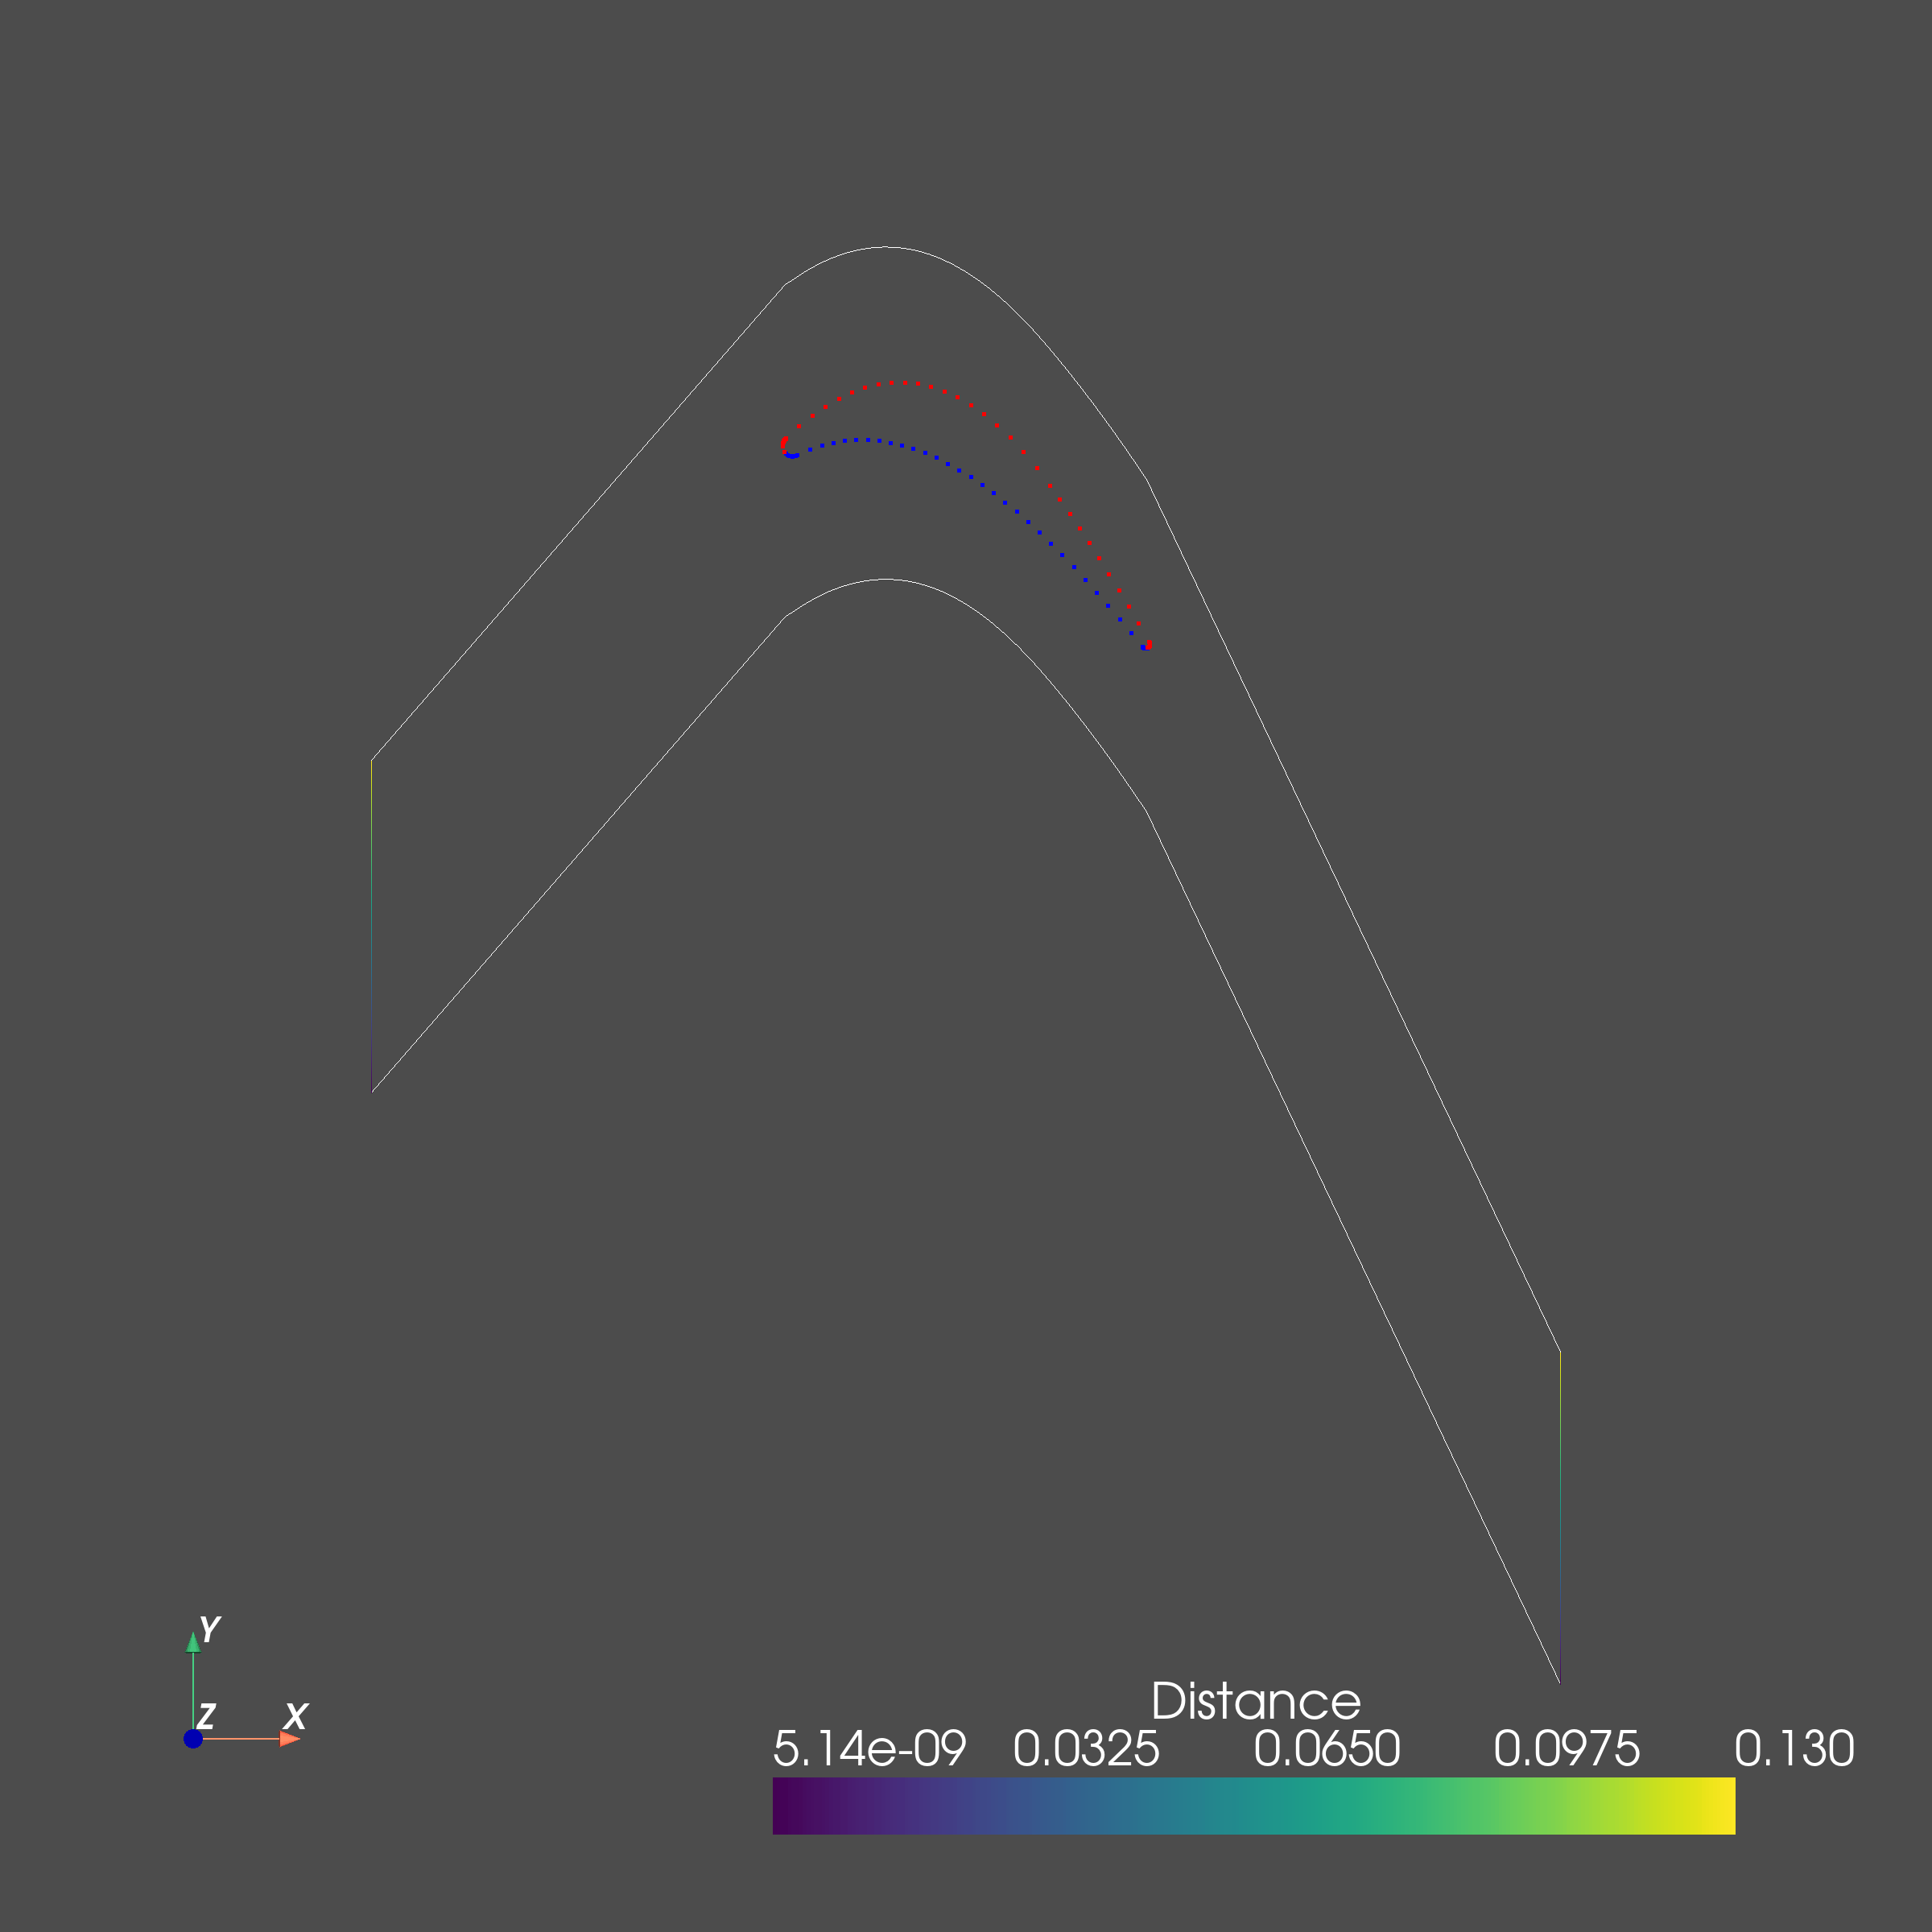

In [3]:
domainparams = DomainParameters()
domainparams.generate_params_by_pointcloud(pts)
domainparams.pitch = .13
domainparams.blade_yshift = 0.0
domain2d = CascadeDomain2D()


domain2d.generate_from_cascade_parameters(domainparams)
path = domain2d.plot_domain()
Image(path, width=1600, height=1600)

In [4]:
meshconfig = MeshConfig()
meshconfig.max_lc = 0.01
meshconfig.min_lc =0.005
meshconfig.bl_thickness = 0.005
meshconfig.bl_growratio = 1.2
meshconfig.bl_size = 1.7e-5
meshconfig.wake_length = domain2d.chordlength*.6
meshconfig.wake_width = domain2d.chordlength*.1
meshconfig.wake_lc = 0.005
meshconfig.fake_yShiftCylinder = 0
meshconfig.bladeres = 200
meshconfig.progression_le_halfss = 1.05
meshconfig.progression_halfss_te = 0.95
meshconfig.progression_te_halfps = 1.05
meshconfig.progression_halfps_le = 0.95

meshpath =  tempfile.mkdtemp() + "/test.cgns"

generate_turbocascade(domain2d,meshconfig, meshpath, verbose=False)


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (BSpline)
Info    : [ 10%] Meshing curve 2 (BSpline)
Info    : [ 10%] Meshing curve 3 (BSpline)
Info    : [ 20%] Meshing curve 4 (BSpline)
Info    : [ 20%] Meshing curve 5 (BSpline)
Info    : [ 30%] Meshing curve 6 (BSpline)
Info    : [ 30%] Meshing curve 7 (BSpline)
Info    : [ 30%] Meshing curve 8 (BSpline)
Info    : [ 40%] Meshing curve 9 (Extruded)
Info    : [ 40%] Meshing curve 10 (Extruded)
Info    : [ 50%] Meshing curve 11 (Extruded)
Info    : [ 50%] Meshing curve 12 (Extruded)
Info    : [ 50%] Meshing curve 13 (Extruded)
Info    : [ 60%] Meshing curve 14 (Extruded)
Info    : [ 60%] Meshing curve 15 (Extruded)
Info    : [ 70%] Meshing curve 16 (Extruded)
Info    : [ 70%] Meshing curve 17 (Extruded)
Info    : [ 80%] Meshing curve 18 (Extruded)
Info    : [ 80%] Meshing curve 19 (Extruded)
Info    : [ 80%] Meshing curve 20 (Extruded)
Info    : [ 90%] Meshing curve 21 (Extruded)
Info    : [ 90%] Meshing curve 22 (Extruded)
Inf

0

lets plot the outcome of the mesh generation algorithm.
as you can see, this method is still experimental although it is implemented in the main branch.
i made the decision because the method is worhtwhile developing further and maintainence as well as advertising it is easier if it is in the main branch.

In [5]:

zslice = tempfile.mkdtemp() + "/zslice.jpg"
xyplane = tempfile.mkdtemp() + "/xyplane.jpg"

mesh = load_mesh(meshpath)

slice = mesh.slice(normal="z", origin=(0, 0, 0.02))
edges = slice.extract_all_edges()

p = pv.Plotter()
p.add_mesh(edges)
p.show_grid()
p.view_yx(negative=True)
p.camera.roll = 0
p.camera.zoom(1)
p.add_axes()
p.screenshot(zslice)

pyvista_ndarray([[[76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76],
                  ...,
                  [76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76]],

                 [[76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76],
                  ...,
                  [76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76]],

                 [[76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76],
                  ...,
                  [76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76]],

                 ...,

                 [[76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76],
                  ...,
                  [76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76]],

                 [[76, 76, 76],
                  [76, 76, 76],
                  [76, 76, 76],
             

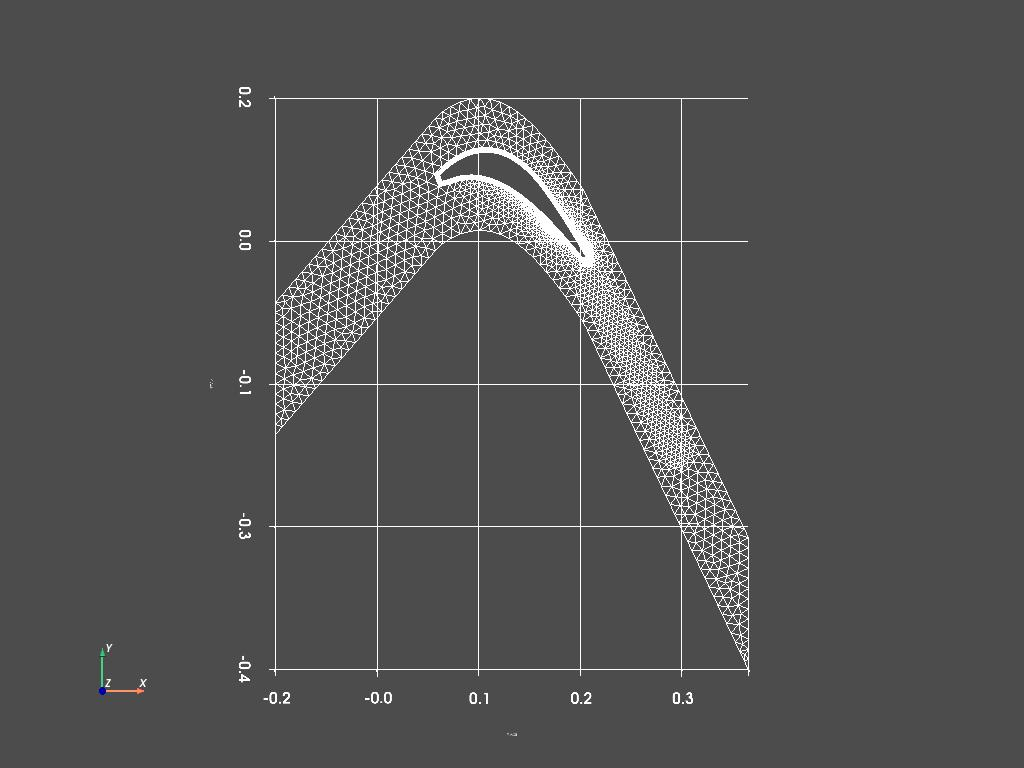

In [6]:
Image(zslice, width=1600, height=1600)


In [7]:
meshpath


'/tmp/tmp8o9map3c/test.cgns'